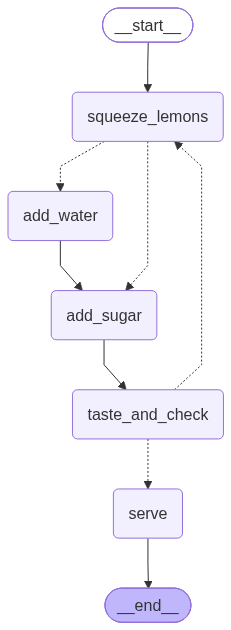

In [1]:
from langgraph.graph import StateGraph
from typing import TypedDict, Dict, Any

# Define the updated state with skip flag and attempt count
class LemonSkipState(TypedDict):
    lemons: int
    sugar: int
    water: str
    juice: str
    mix: str
    final: str
    sweet: bool
    attempts: int
    skip_water: bool  # controls skipping

# Nodes
def squeeze_lemons(state: Dict[str, Any]) -> Dict[str, Any]:
    state["juice"] = f"Juice from {state['lemons']} lemons"
    return state

def add_water(state: Dict[str, Any]) -> Dict[str, Any]:
    state["mix"] = f"{state['juice']} + {state['water']} water"
    return state

def add_sugar(state: Dict[str, Any]) -> Dict[str, Any]:
    state["sugar"] += 1
    state["attempts"] += 1
    state["mix"] = f"{state['juice']} + {state['water']} water + {state['sugar']} spoons sugar"
    return state

def taste_and_check(state: Dict[str, Any]) -> Dict[str, Any]:
    # Consider sweet if sugar >= 2
    state["sweet"] = state["sugar"] >= 2
    # After first loop, skip water
    if state["attempts"] >= 1:
        state["skip_water"] = True
    return state

def serve(state: Dict[str, Any]) -> Dict[str, Any]:
    state["final"] = f"{state['mix']} → Served!"
    return state

# Decision function to skip water
def route_after_squeeze(state: Dict[str, Any]) -> str:
    return "add_sugar" if state.get("skip_water", False) else "add_water"

# Looping condition
def check_sweetness(state: Dict[str, Any]) -> str:
    return "serve" if state["sweet"] else "squeeze_lemons"

# Build graph
builder = StateGraph(LemonSkipState)
builder.add_node("squeeze_lemons", squeeze_lemons)
builder.add_node("add_water", add_water)
builder.add_node("add_sugar", add_sugar)
builder.add_node("taste_and_check", taste_and_check)
builder.add_node("serve", serve)

builder.set_entry_point("squeeze_lemons")

# After squeezing, route based on skip_water
builder.add_conditional_edges("squeeze_lemons", route_after_squeeze, {
    "add_water": "add_water",
    "add_sugar": "add_sugar"
})

builder.add_edge("add_water", "add_sugar")
builder.add_edge("add_sugar", "taste_and_check")

builder.add_conditional_edges("taste_and_check", check_sweetness, {
    "serve": "serve",
    "squeeze_lemons": "squeeze_lemons"
})

builder.set_finish_point("serve")

# Compile and run
#graph = builder.compile()

from IPython.display import Image, display
graph = builder.compile()
# Visualize
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed:", e)

initial_state = {
    "lemons": 4,
    "sugar": 0,
    "water": "1 glass",
    "juice": "",
    "mix": "",
    "final": "",
    "sweet": False,
    "attempts": 0,
    "skip_water": False
}

result = graph.invoke(initial_state)



In [2]:
import pandas as pd
result_df = pd.DataFrame([result])
result_df


,lemons,sugar,water,juice,mix,final,sweet,attempts,skip_water
0,4,2,1 glass,Juice from 4 lemons,Juice from 4 lemons + 1 glass water + 2 spoons...,Juice from 4 lemons + 1 glass water + 2 spoons...,True,2,True


In [ ]:
----------------------E-Commerce Order Processing Code-------------

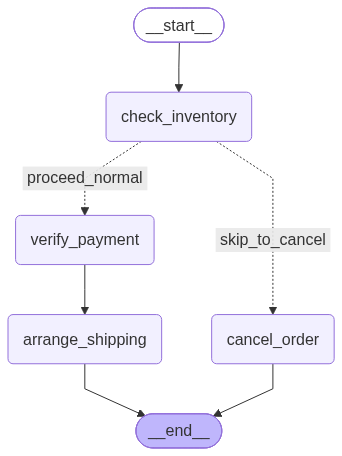

--- TEST CASE 1: In Stock (Normal Flow) ---
--- Step 1: Checking Inventory ---
--- Step 2: Verifying Payment ---
--- Step 3: Arranging Shipping ---

--- TEST CASE 2: Out of Stock (Skips Payment & Shipping) ---
--- Step 1: Checking Inventory ---
--- Step (Skipped Payment & Shipping): Cancelling Order ---

📊 Final Report for Skip Case:


,order_id,item_name,quantity,total_price,inventory_status,payment_status,shipping_status,final_status
0,ORD-102,Gaming Chair,10,14999.0,Out of Stock ❌,Skipped / Not Required 🚫,Skipped / Not Required 🚫,Order Cancelled due to Out of Stock! ⚠️
1,ORD-101,Wireless Mouse,2,999.0,In Stock ✅,Payment Verified 💳,Shipped via Express Delivery 🚚,Order Completed Successfully! 🎉


In [9]:
from langgraph.graph import StateGraph
from typing import TypedDict, Dict, Any
import pandas as pd
from IPython.display import Image, display

# 1. Define State
class OrderState(TypedDict):
    order_id: str
    item_name: str
    quantity: int
    total_price: float
    inventory_status: str
    payment_status: str
    shipping_status: str
    final_status: str

# 2. Define Nodes
def check_inventory(state: Dict[str, Any]) -> Dict[str, Any]:
    print("--- Step 1: Checking Inventory ---")
    # Quantity 5-ku mela irundha out of stock nu vachukrom
    if state["quantity"] <= 5:
        state["inventory_status"] = "In Stock ✅"
    else:
        state["inventory_status"] = "Out of Stock ❌"
    return state

def verify_payment(state: Dict[str, Any]) -> Dict[str, Any]:
    print("--- Step 2: Verifying Payment ---")
    state["payment_status"] = "Payment Verified 💳"
    return state

def arrange_shipping(state: Dict[str, Any]) -> Dict[str, Any]:
    print("--- Step 3: Arranging Shipping ---")
    state["shipping_status"] = "Shipped via Express Delivery 🚚"
    state["final_status"] = "Order Completed Successfully! 🎉"
    return state

# 🚫 Skip Node (If stock is not available, jump straight here)
def cancel_order(state: Dict[str, Any]) -> Dict[str, Any]:
    print("--- Step (Skipped Payment & Shipping): Cancelling Order ---")
    state["payment_status"] = "Skipped / Not Required 🚫"
    state["shipping_status"] = "Skipped / Not Required 🚫"
    state["final_status"] = "Order Cancelled due to Out of Stock! ⚠️"
    return state

# 3. Router Condition for Skipping
def should_proceed(state: Dict[str, Any]) -> str:
    if "Out of Stock" in state["inventory_status"]:
        return "skip_to_cancel"  # Payment & Shipping-ah skip pannum
    else:
        return "proceed_normal"   # Normal flow-ku pogum

# 4. Build Graph
builder = StateGraph(OrderState)

builder.add_node("check_inventory", check_inventory)
builder.add_node("verify_payment", verify_payment)
builder.add_node("arrange_shipping", arrange_shipping)
builder.add_node("cancel_order", cancel_order)

builder.set_entry_point("check_inventory")

# 🔀 Conditional Edge for Skipping
builder.add_conditional_edges(
    "check_inventory",
    should_proceed,
    {
        "skip_to_cancel": "cancel_order",     # Skip target
        "proceed_normal": "verify_payment"    # Normal path
    }
)

# Normal flow connection
builder.add_edge("verify_payment", "arrange_shipping")

# Finish points
builder.set_finish_point("arrange_shipping")
builder.set_finish_point("cancel_order")

graph = builder.compile()

# ✅ Visualize Graph Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed:", e)

# 5. Test Case 1: Normal Flow (Quantity = 2 -> In Stock)
print("--- TEST CASE 1: In Stock (Normal Flow) ---")
result_normal = graph.invoke({
    "order_id": "ORD-101",
    "item_name": "Wireless Mouse",
    "quantity": 2,
    "total_price": 999.0,
    "inventory_status": "",
    "payment_status": "",
    "shipping_status": "",
    "final_status": ""
})

# Test Case 2: Skip Flow (Quantity = 10 -> Out of Stock, skips payment & shipping)
print("\n--- TEST CASE 2: Out of Stock (Skips Payment & Shipping) ---")
result_skip = graph.invoke({
    "order_id": "ORD-102",
    "item_name": "Gaming Chair",
    "quantity": 10,
    "total_price": 14999.0,
    "inventory_status": "",
    "payment_status": "Skipped",
    "shipping_status": "",
    "final_status": ""
})

# Display Result as Pandas DataFrame
print("\n📊 Final Report for Skip Case:")
result_df = pd.DataFrame([result_skip,result_normal])
try:
    display(result_df)
except:
    print(result_df)